In [1]:
import numpy as np
import seaborn as sns
import pandas as pd 
import matplotlib.pyplot as plt


Insurance Dataset : https://docs.google.com/spreadsheets/d/1dAc3E4U-gBzihJ6HLM2kYVDAqQthdReg20zwwaplTW8/edit?usp=share_link

In [2]:
insurance=pd.read_csv('content/insurance_data - insurance_data.csv')

In [3]:
insurance.head()

,index,PatientID,age,gender,bmi,bloodpressure,diabetic,children,smoker,region,claim
0,0,1,39.0,male,23.2,91,Yes,0,No,southeast,1121.87
1,1,2,24.0,male,30.1,87,No,0,No,southeast,1131.51
2,2,3,NaN,male,33.3,82,Yes,0,No,southeast,1135.94
3,3,4,NaN,male,33.7,80,No,0,No,northwest,1136.40
4,4,5,NaN,male,34.1,100,No,0,No,northwest,1137.01


### Q-1: What is the probability distribution of age in the insurance dataset?

-- Find out using the KDE method

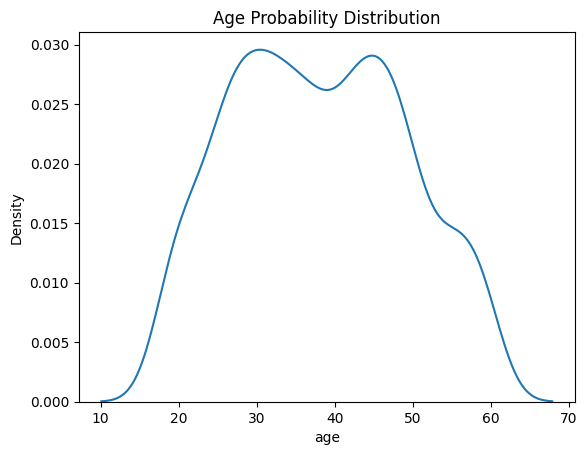

In [4]:
# code here
sns.kdeplot(insurance['age'])
plt.title("Age Probability Distribution")
plt.show()

### Q-2: What is the probability of a patient having a BMI greater than 30?

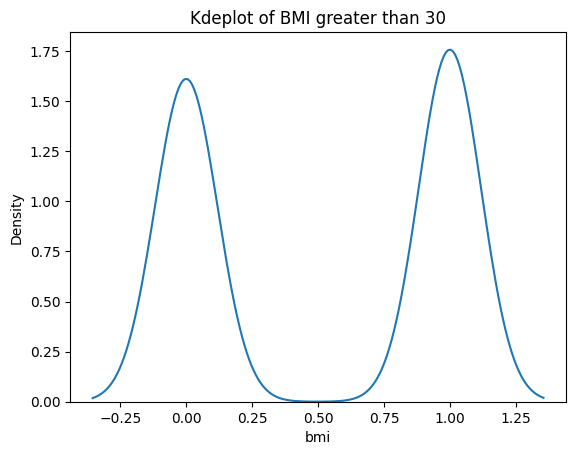

In [5]:
# answer here
sns.kdeplot(insurance['bmi']>30)
plt.title('Kdeplot of BMI greater than 30')
plt.show()

### Q-3: Plot distribution plot of claim for Smoker and non smoker. What changes you see in the plot?

In [6]:
# code here 
df1=insurance(['smoker']=='Yes').groupby('claim')
sns.distplot(
    data=df1,
    kind='hist',
)


# code here 
df2=insurance(['smoker']=='Yes').groupby('claim')
sns.distplot(
    data=df2,
    kind='hist',
)

TypeError: 'DataFrame' object is not callable

### Q-4: Plot the 2D probability density plot of claim and age in the insurance dataset?

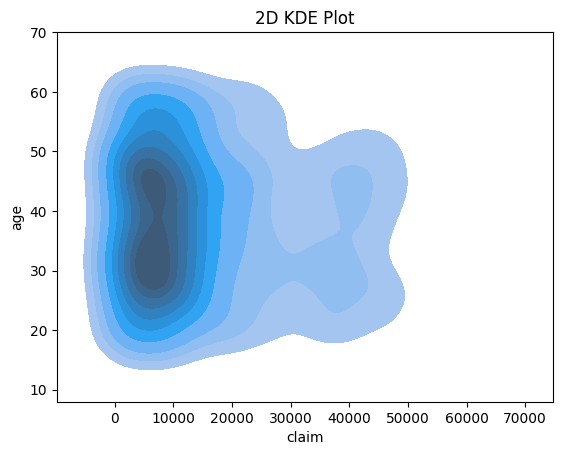

In [ ]:
# code here 
# method 1 

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde


x=insurance['claim']
y=insurance['age']

data=np.vstack([x,y])
kde=gaussian_kde(data)



# method -2 
sns.kdeplot(x=x,y=y,fill=True)
plt.title("2D KDE Plot")
plt.show()


### Q-5: How does the disribution of claim changes for different region? Plot density plot and note down the observations

In [ ]:
# code here
sns.kdeplot(insurance['claim'],fill=True)
plt.titel

### Q6: Plot PDF and CDF of claim in insurance data

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt




# ! SORT DATA (important for CDF)
charges = np.sort(insurance['charges'])

# ! COMPUTE CDF VALUES
cdf = np.arange(1, len(charges)+1) / len(charges)

# ! CREATE PLOTS
plt.figure(figsize=(12,5))

# ---------------- PDF ----------------
plt.subplot(1,2,1)
sns.kdeplot(insurance['charges'], fill=True)   # smooth density curve
plt.title("PDF of Charges")
plt.xlabel("Charges")

# ---------------- CDF ----------------
plt.subplot(1,2,2)
plt.plot(charges, cdf)   # cumulative curve
plt.title("CDF of Charges")
plt.xlabel("Charges")
plt.ylabel("Probability")

plt.tight_layout()
plt.show()

KeyError: 'charges'

### Q-7: Given a probability density function f(x) = 2x for 0 <= x <= 1 and f(x) = 0 otherwise, compute the cumulative distribution function F(x) and plot it. Use this to find the probability that X is greater than 0.5.

In [ ]:
# ! CREATE X VALUES
x = np.linspace(-0.5, 1.5, 100)

# ! DEFINE CDF FUNCTION
F = []
for val in x:
    if val < 0:
        F.append(0)
    elif val <= 1:
        F.append(val**2)   # CDF = x^2
    else:
        F.append(1)

# ! PLOT
plt.plot(x, F)
plt.title("CDF of f(x) = 2x")
plt.xlabel("x")
plt.ylabel("F(x)")
plt.show()

### Q-8: In a manufacturing process, the thickness of a certain material is known to be normally distributed with a mean of 1.2 mm and a standard deviation of 0.05 mm. What is the probability density function of the thickness? Plot the PDF and use it to compute the probability that the thickness is between 1.1 mm and 1.3 mm.

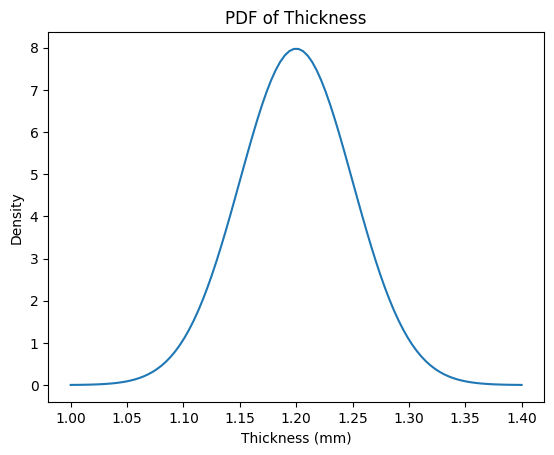

In [10]:
# answer here
# ! CREATE X VALUES
x = np.linspace(1.0, 1.4, 100)

# ! NORMAL PDF FORMULA
mu = 1.2
sigma = 0.05

pdf = (1/(sigma * np.sqrt(2*np.pi))) * np.exp(-((x - mu)**2) / (2*sigma**2))

# ! PLOT
plt.plot(x, pdf)
plt.title("PDF of Thickness")
plt.xlabel("Thickness (mm)")
plt.ylabel("Density")
plt.show()

In [11]:
from scipy.stats import norm

mu = 1.2
sigma = 0.05

# ! COMPUTE PROBABILITY
prob = norm.cdf(1.3, mu, sigma) - norm.cdf(1.1, mu, sigma)

print(prob)

0.9544997361036416


### Q-9 : A data scientist is investigating the distribution of customer ages in a retail store. She collects a sample of 100 ages and estimates the probability density function using kernel density estimation. What bandwidth should she choose to obtain the best estimate?

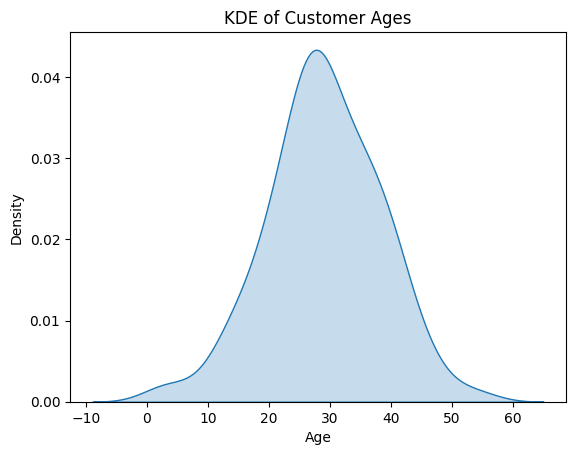

In [12]:
# answer here

# In Kernel Density Estimation (KDE), bandwidth is the smoothing parameter
# It controls the smoothness of the density curve (small → overfitting, large → underfitting)

# Generate a sample of 100 customer ages (realistic random data)
data = np.random.normal(loc=30, scale=10, size=100)   # mean age ~30, std ~10

# Plot KDE (Seaborn uses Silverman’s rule by default for bandwidth selection)
sns.kdeplot(data, fill=True)

# Labels (important for assignment)
plt.title("KDE of Customer Ages")
plt.xlabel("Age")
plt.ylabel("Density")

plt.show()